# 30 – Erster Entwurf: Graph Neural Network (GNN) für die HAST-Früherkennung

**Zweck:** Prüfen, ob ein GNN das Normalverhaltensmodell aus NB 17 verbessert, und zwar **wegen des Netzes**.
Das GNN darf für jede Station auch die Messwerte ihrer Nachbarn im Netz (NB 16) vom selben Tag verwenden.

**Die Idee in einem Satz:** NB 17 sagt für jede Station und jeden Heiztag vorher, was normal wäre. Übrig bleibt
die Abweichung z. Das GNN versucht, diesen Rest aus Wetter, Lage im Netz und den Nachbarn zu erklären. Was es
erklären kann, kam von außen (Netz, Wetter, Vorlauf) und ist kein Fehler der Station.

**Aufbau als Vergleich (Ablation)**

| Modell | Was es weiß |
|---|---|
| **NB 17 allein** | Kennlinie der Station gegen die Tagesmitteltemperatur |
| **ohne Netz (MLP)** | zusätzlich Temperatur der Vortage, Wochenende, Jahreszeit, eigener Vorlauf, Lage im Netz als feste Zahlen |
| **GNN (GraphSAGE)** | zusätzlich die Messwerte der Nachbarn am selben Tag (z beider Kanäle, Vorlauf), über bis zu 2 Kanten |

- „ohne Netz“ und „GNN“ sind **dasselbe Modell**, einmal ohne und einmal mit Kanten. Der Unterschied zwischen
  beiden ist damit genau der Beitrag des Netzes.
- **Was schon feststeht (NB 17, Abschnitt 15):** Nachbarn weichen bei Abkühlung und Wassermenge nicht gemeinsam
  ab. Die Erwartung ist deshalb, dass das GNN kaum besser ist als ohne Netz. Dieses Notebook prüft das mit einem
  echten Modell statt mit Korrelationen.

**Eingaben** (das Notebook schreibt nichts, solange `SPEICHERN = False`)
- NB 06: `data/processed/hast_tage.csv`
- NB 17: `normalmodell_tage.csv`, `normalmodell_stationen.csv`, `normalmodell_treffer.csv`, `normalmodell_wirkung.csv`
- Begehungen: `data/processed/begehungen_aufbereitet.csv`
- NB 16: `kanten_roh_bereinigt.csv`, `hast_zaehler.csv`, `zaehler_adressen.csv`, `geocode_cache.csv`,
  `kanten_auf_rohren.csv`, `hast_positionen.csv` in `notebooks/`

**Laufzeit:** rund 15 Minuten, fast alles in Abschnitt 6.

## 1 · Setup & Parameter

Alle Stellschrauben stehen in dieser Zelle. Sie wurden **vor** dem ersten Lauf festgelegt und nicht an den
Ergebnissen nachgestellt (sonst passt man das Modell an die Prüfzeit an, siehe Abschnitt 10).

In [1]:
import re
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy import stats

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams["figure.facecolor"] = "white"

ROOT = Path.cwd().resolve()
while not (ROOT / "notebooks").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROC = ROOT / "data" / "processed"   # Ausgaben von NB 06 und NB 17
NETZ = ROOT / "notebooks"            # Tabellen aus NB 16

# --- Quelle (Annahme, bis die echte Lage der Heizzentrale bekannt ist) ------------------
QUELLE_LAT, QUELLE_LON = 49.797434, 10.346401   # Steigerwald-Landschulheim laut OpenStreetMap
QUELLE_RADIUS_M = 120     # Nodes bis zu diesem Luftlinienabstand gelten als direkt an der Quelle

# --- Tage und Merkmale --------------------------------------------------------------------
T_HEIZGRENZE = 15.0       # nur Heiztage (wie NB 06 und NB 17)
ABSTAND_BEGEHUNG = 14     # Tage ab so vielen Tagen vor der ersten Begehung zaehlen nicht als "normal"
VORLAUF_BEREICH = (30, 95)  # plausible Vorlauftemperaturen in °C, alles andere gilt als Messfehler
MIN_STATIONEN_JE_TAG = 10   # Flottenmedian des Vorlaufs nur an Tagen mit so vielen Stationen
Z_DECKEL = 8.0            # z-Werte werden fuer Training und Bewertung bei ±8 gekappt

# --- Modell und Training ------------------------------------------------------------------
VERSTECKT = 32            # Breite der beiden versteckten Schichten
LERNRATE = 3e-3
GEWICHTSZERFALL = 1e-4    # L2-Strafe auf die Gewichte
HUBER_DELTA = 1.5         # Verlust: quadratisch bis 1,5 s, darueber linear (robust gegen Ausreisser)
EPOCHEN_MAX = 200
GEDULD = 12               # Abbruch, wenn die innere Validierung so viele Epochen nicht besser wird
BATCH_TAGE = 16
MASKEN_ANTEIL = 0.3       # Anteil der Stationen, deren Messwerte im Training je Tag verborgen werden
MASKEN_GRUPPEN = 4        # bei der Vorhersage: Stationen in 4 Gruppen nacheinander verbergen
INNERE_VALIDIERUNG = 0.15 # Anteil der Trainingswochen fuer den Abbruch
SEEDS = [1, 2, 3]         # je Variante und Fold drei Laeufe, die Vorhersagen werden gemittelt
MIN_TAGE_STATION = 30     # Stationen mit weniger Pruef-Tagen fehlen im Stationsvergleich
SPEICHERN = False         # True: Vorhersagen nach data/processed/gnn_vorhersagen.csv schreiben

KANAELE = {"kwh_pro_m3": "Abkühlung (kWh/m³)", "log_volumen": "Wassermenge (Tagesvolumen)"}
VARIANTEN = {"ohne_netz": "ohne Netz (MLP)", "gnn": "GNN (GraphSAGE)"}

# --- Darstellung (Farben aus NB 06/17) ---------------------------------------------------
FARBE_KANAL = {"kwh_pro_m3": "#2a78d6", "log_volumen": "#c74b12"}
FARBE_VARIANTE = {"nb17": "#c3c2b7", "ohne_netz": "#52514e", "gnn": "#4a3aa7"}
TINTE, TINTE_LEISE, GITTER, ACHSE, FLAECHE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#f1f0ec"


def stil(ax):
    """Zurueckhaltende Achsen: nur links/unten, feines Gitter (wie NB 06)."""
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(ACHSE)
    ax.tick_params(colors=TINTE_LEISE, labelsize=9)
    ax.grid(color=GITTER, linewidth=0.6)
    ax.set_axisbelow(True)

**Was macht die Zelle?**
- **Quelle (Annahme):** Die Heizzentrale wird am Steigerwald-Landschulheim angenommen. Der Wärmenetzplan
  (`data/raw/Wärmenetzplan[38].pdf`) zeigt die Hauptleitungen von dort ausgehend. Die Koordinate stammt aus
  OpenStreetMap. Sobald die echte Lage bekannt ist, nur `QUELLE_LAT` / `QUELLE_LON` ändern.
- **Huber-Verlust:** Fehler bis 1,5 s zählen quadratisch, größere nur linear. Einzelne Tage mit z = 8 sollen das
  Lernen nicht bestimmen.
- **Masken:** siehe Abschnitt 5. Sie verhindern, dass das GNN den eigenen Messwert einer Station über ihre
  Nachbarn zurückbekommt.
- **Warum numpy und nicht PyTorch?** Für Intel-Macs gibt es PyTorch nur bis Version 2.2, und die verträgt sich
  nicht mit numpy 2 in der Umgebung `projektseminar`. Das Modell ist klein (rund 60 Zeilen in Abschnitt 5) und
  läuft so ohne Installation, jeder Rechenschritt ist sichtbar. Auf Colab oder Linux wäre derselbe Aufbau mit
  PyTorch Geometric (`SAGEConv`) ein paar Zeilen.

## 2 · Daten laden

- **z aus NB 17:** je Station, Kanal und verwendbarem Heiztag die Abweichung von der eigenen Kennlinie in
  Streuungen s. Das ist das, was das GNN erklären soll.
- **Erste Begehung je Zähler** aus drei Quellen: Begehungstabelle, Termine der NB-17-Prüfungen und Referenzende
  „vor Begehung“ + 14 Tage. Ab 14 Tage vor der ersten Begehung gilt eine Station nicht mehr als „normal“. Diese
  Tage werden weder gelernt noch bewertet, aber vorhergesagt (Abschnitt 8).

In [2]:
for datei in ["normalmodell_tage.csv", "normalmodell_stationen.csv", "hast_tage.csv", "begehungen_aufbereitet.csv"]:
    if not (PROC / datei).is_file():
        raise FileNotFoundError(f"{datei} fehlt in {PROC} - zuerst NB 06 und NB 17 ausfuehren")

verlauf = pd.read_csv(PROC / "normalmodell_tage.csv", parse_dates=["datum"])      # NB 17: z je Station, Kanal, Tag
ref_tab = pd.read_csv(PROC / "normalmodell_stationen.csv", parse_dates=["ref_start", "ref_ende"])
tage = pd.read_csv(PROC / "hast_tage.csv", parse_dates=["datum"])                   # NB 06: alle Tageswerte
tage["zaehler"] = tage["zaehler"].astype(int)

# Erste Begehung je Zaehler: Begehungstabelle plus die Termine, die NB 17 verwendet hat
quellen = [pd.read_csv(PROC / "begehungen_aufbereitet.csv", sep=";", encoding="utf-8-sig")
           .rename(columns={"meter": "zaehler"})[["zaehler", "datum"]]]
for datei in ["normalmodell_treffer.csv", "normalmodell_wirkung.csv"]:
    if (PROC / datei).is_file():
        quellen.append(pd.read_csv(PROC / datei)[["zaehler", "datum"]])
vor_beg = ref_tab[ref_tab["ende_grund"] == "vor Begehung"]      # NB 17: Referenz endet 14 Tage vor der Begehung
quellen.append(pd.DataFrame({"zaehler": vor_beg["zaehler"],
                             "datum": vor_beg["ref_ende"] + pd.Timedelta(days=ABSTAND_BEGEHUNG)}))
termine = pd.concat(quellen, ignore_index=True)
termine["zaehler"] = pd.to_numeric(termine["zaehler"], errors="coerce")
termine["datum"] = pd.to_datetime(termine["datum"], errors="coerce")
termine = termine.dropna().astype({"zaehler": "int64"})
erste_begehung = termine.groupby("zaehler")["datum"].min()

print(f"NB 17: {verlauf['zaehler'].nunique()} Stationen, {verlauf['datum'].nunique()} Heiztage "
      f"({verlauf['datum'].min():%d.%m.%Y} bis {verlauf['datum'].max():%d.%m.%Y})")
print(f"NB 06: {tage['zaehler'].nunique()} Zaehler, davon mit Vorlauf an Heiztagen: "
      f"{tage.loc[(tage['t_mittel_c'] < T_HEIZGRENZE) & tage['vorlauf_c'].notna(), 'zaehler'].nunique()}")
print(f"Zaehler mit Begehung: {len(erste_begehung)} (erste: {erste_begehung.min():%d.%m.%Y}, "
      f"letzte: {erste_begehung.max():%d.%m.%Y})")

NB 17: 89 Stationen, 884 Heiztage (02.11.2021 bis 09.06.2025)
NB 06: 93 Zaehler, davon mit Vorlauf an Heiztagen: 93
Zaehler mit Begehung: 56 (erste: 26.08.2024, letzte: 16.09.2025)


## 3 · Netz und Lage im Netz

Ein GNN braucht drei Dinge: welche Knoten, welche Kanten, und was jeder Knoten über sich weiß.

- **Kanten** aus `Nodes_Edges.ods` (NB 16), **ohne Richtung.** Die Pfeile passen zu keiner Quelle: Gegen die
  angenommene Quelle zeigen etwa gleich viele hin wie weg (Ausgabe unten). Was die Pfeile bedeuten, muss die
  ÜZ klären.
- **Quelle** als zusätzlicher Knoten. Alle Adressen bis `QUELLE_RADIUS_M` Luftlinie werden mit ihr verbunden,
  weil auf dem Plan mehrere Hauptleitungen von der Schule ausgehen.
- **Lage-Merkmale je Adresse**
  - **Hops zur Quelle:** Zahl der Kanten bis zur Quelle (0 = direkt dran)
  - **Rohrweg zur Quelle:** Meter auf den Rohren. Die Rohrlängen kommen aus NB 16 Abschnitt 8; Kanten ohne
    Rohrweg (Adressen ohne Koordinate) bekommen den Median
  - **Last dahinter:** Summe der Anschlusswerte, die durch diese Adresse versorgt werden (im Baum der
    kürzesten Rohrwege ab der Quelle). Groß = Hauptstrang
  - **Randlage** und **Strangende:** wie in NB 17 Abschnitt 16
  - **DN am Anschluss:** Rohrdimension am Hausanschluss aus NB 16

In [3]:
def netz_key(s):
    """Adressschluessel wie norm_adresse in NB 16, z. B. 'Hauptstr. 12 a' -> 'hauptstrasse 12a'."""
    s = str(s).strip().lower()
    for a, b in {"ß": "ss", "ä": "ae", "ö": "oe", "ü": "ue"}.items():
        s = s.replace(a, b)
    s = re.sub(r"str\.", "strasse", s)
    s = re.sub(r"[^\w\s-]", " ", s)
    s = re.sub(r"str(?=\s|$)", "strasse", s)
    s = re.sub(r"\s+", " ", s).strip()
    return re.sub(r"(\d+)\s+([a-z])\b", r"\1\2", s)


def meter(lat1, lon1, lat2, lon2):
    """Abstand in Metern (fuer ein paar hundert Meter reicht die flache Naeherung)."""
    return np.hypot((lat1 - lat2) * 111_320, (lon1 - lon2) * 111_320 * np.cos(np.radians(49.8)))


lies = dict(sep=";", encoding="utf-8-sig", dtype=str)
for datei in ["kanten_roh_bereinigt.csv", "hast_zaehler.csv", "zaehler_adressen.csv", "geocode_cache.csv",
              "kanten_auf_rohren.csv", "hast_positionen.csv"]:
    if not (NETZ / datei).is_file():
        raise FileNotFoundError(f"{datei} fehlt in {NETZ} - zuerst NB 16 ausfuehren")

# 1) Netz der Adressen, ohne Richtung (die Pfeile passen zu keiner Quelle, siehe Text)
kanten = pd.read_csv(NETZ / "kanten_roh_bereinigt.csv", **lies).dropna(subset=["von_key", "nach_key"])
netz = nx.Graph()
netz.add_edges_from(zip(kanten["von_key"], kanten["nach_key"]))

# 2) Zaehler -> Adress-Node (wie NB 17 Abschnitt 15), nur Zaehler mit Tageswerten
stamm = pd.read_csv(NETZ / "hast_zaehler.csv", **lies)
jahre = pd.read_csv(NETZ / "zaehler_adressen.csv", **lies)
jahre = jahre.melt(id_vars="adresse", value_vars=[c for c in jahre.columns if c.isdigit()], value_name="zaehler")
zuordnung = pd.concat([stamm[["zaehler", "adresse_key"]].rename(columns={"adresse_key": "node"}),
                       pd.DataFrame({"zaehler": jahre["zaehler"], "node": jahre["adresse"].map(netz_key)})])
zuordnung["zaehler"] = pd.to_numeric(zuordnung["zaehler"], errors="coerce")
zuordnung = zuordnung.dropna().astype({"zaehler": "int64"})
zuordnung = zuordnung[zuordnung["node"].isin(netz.nodes) & zuordnung["zaehler"].isin(set(tage["zaehler"]))]
node_je = zuordnung.drop_duplicates().groupby("zaehler")["node"].first()

# 3) Lage je Adresse: Quelle als zusaetzlicher Knoten, Rohrlaengen aus NB 16 als Kantengewicht
pos = (pd.read_csv(NETZ / "geocode_cache.csv", sep=";", encoding="utf-8-sig")
       .drop_duplicates("key").set_index("key")[["lat", "lon"]].reindex(list(netz.nodes)).dropna())
rohre = pd.read_csv(NETZ / "kanten_auf_rohren.csv", sep=";", encoding="utf-8-sig")
laenge = {frozenset((netz_key(v), netz_key(n))): l
          for v, n, l in zip(rohre["von"], rohre["nach"], rohre["laenge_rohr_m"]) if pd.notna(l)}
ersatz_m = float(np.nanmedian(list(laenge.values())))       # Kanten ohne Rohrweg: Median der Rohrlaengen
gewichtet = nx.Graph()
for u, v in netz.edges:
    gewichtet.add_edge(u, v, m=laenge.get(frozenset((u, v)), ersatz_m))
abstand_quelle = meter(pos["lat"], pos["lon"], QUELLE_LAT, QUELLE_LON)
an_quelle = abstand_quelle[abstand_quelle <= QUELLE_RADIUS_M]
for adr, m in an_quelle.items():
    gewichtet.add_edge("QUELLE", adr, m=float(m))
if an_quelle.empty:
    raise ValueError("Kein Node im Umkreis der Quelle - QUELLE_RADIUS_M vergroessern")

hops = nx.single_source_shortest_path_length(gewichtet, "QUELLE")
vorgaenger, rohrweg = nx.dijkstra_predecessor_and_distance(gewichtet, "QUELLE", weight="m")

kw_station = tage.groupby("zaehler")["anschlusswert_kw"].median()
kw_adresse = {adr: float(kw_station.reindex(node_je.index[node_je == adr]).sum()) for adr in netz.nodes}
# Anschlusswert, der durch eine Adresse hindurch versorgt wird (Baum der kuerzesten Rohrwege ab der Quelle)
last = dict(kw_adresse)
for adr in sorted(rohrweg, key=rohrweg.get, reverse=True):
    if adr != "QUELLE" and vorgaenger[adr] and vorgaenger[adr][0] != "QUELLE":
        last[vorgaenger[adr][0]] += last[adr]

ab_alle = dict(nx.all_pairs_shortest_path_length(netz))
hp = pd.read_csv(NETZ / "hast_positionen.csv", sep=";", encoding="utf-8-sig")
dn = hp.assign(key=hp["adresse"].map(netz_key)).drop_duplicates("key").set_index("key")["dn"]

lage = pd.DataFrame(index=pd.Index(list(netz.nodes), name="adresse"))
lage["hops_quelle"] = [hops.get(a, np.nan) - 1 for a in lage.index]          # 0 = direkt an der Quelle
lage["rohrweg_m"] = [rohrweg.get(a, np.nan) for a in lage.index]
lage["last_kw"] = [last[a] for a in lage.index]
lage["randlage"] = [np.mean([d for m, d in ab_alle[a].items() if m != a]) for a in lage.index]
lage["strangende"] = [float(netz.degree(a) == 1) for a in lage.index]
lage["dn"] = dn.reindex(lage.index).to_numpy(dtype=float)

print(f"Netz: {netz.number_of_nodes()} Adressen, {netz.number_of_edges()} Kanten; "
      f"{len(pos)} Adressen mit Koordinate; Rohrlaenge fuer {len(laenge)} Kanten, sonst {ersatz_m:.0f} m")
print(f"Quelle: {len(an_quelle)} Adressen im Umkreis von {QUELLE_RADIUS_M} m "
      f"(naechste {an_quelle.min():.0f} m entfernt)")
print(f"Zaehler mit Tageswerten und Adresse im Netz: {len(node_je)}")
display(lage.describe().T.round(1))

# Pfeilrichtung der Kanten gegen die angenommene Quelle
richtung = [hops[n] - hops[v] for v, n in zip(kanten["von_key"], kanten["nach_key"])]
print(f"Kanten, deren Pfeil von der Quelle weg zeigt: {sum(r > 0 for r in richtung)}, "
      f"zur Quelle hin: {sum(r < 0 for r in richtung)}")

Netz: 110 Adressen, 110 Kanten; 92 Adressen mit Koordinate; Rohrlaenge fuer 75 Kanten, sonst 55 m
Quelle: 8 Adressen im Umkreis von 120 m (naechste 29 m entfernt)
Zaehler mit Tageswerten und Adresse im Netz: 84


,count,mean,std,min,25%,50%,75%,max
hops_quelle,110.0,9.4,6.5,0.0,4.0,9.0,13.0,25.0
rohrweg_m,110.0,677.0,429.9,29.5,303.7,628.7,949.9,1748.4
last_kw,110.0,96.0,128.5,0.0,10.0,48.0,113.0,545.0
randlage,110.0,16.1,3.7,10.3,13.1,15.7,19.1,25.9
strangende,110.0,0.2,0.4,0.0,0.0,0.0,0.0,1.0
dn,81.0,34.7,9.8,32.0,32.0,32.0,32.0,90.0


Kanten, deren Pfeil von der Quelle weg zeigt: 51, zur Quelle hin: 54


**Wie man die Ausgabe liest**
- Die Tabelle zeigt die Spannweite der Lage-Merkmale über alle Adressen.
- **Pfeilrichtung:** Zeigten die Pfeile die Fließrichtung des Vorlaufs ab dieser Quelle, müssten fast alle „von
  der Quelle weg“ zeigen. Bei etwa halbe-halbe ist entweder die Quelle falsch angenommen, oder die Pfeile
  bedeuten etwas anderes (z. B. die Reihenfolge, in der die Häuser erfasst wurden).

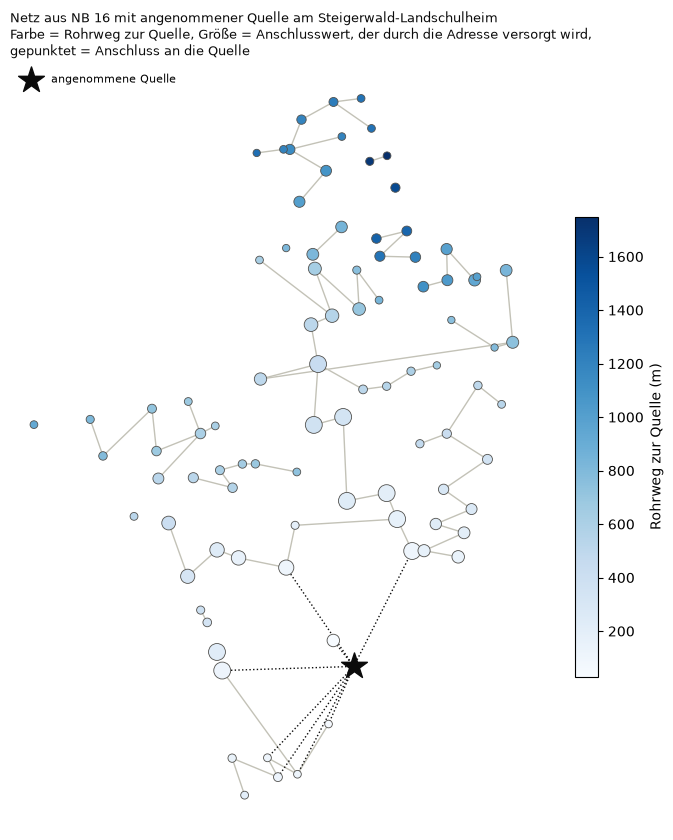

In [4]:
fig, ax = plt.subplots(figsize=(8, 8.5))
for u, v in netz.edges:
    if u in pos.index and v in pos.index:
        ax.plot(pos.loc[[u, v], "lon"], pos.loc[[u, v], "lat"], color=ACHSE, linewidth=1, zorder=1)
for adr in an_quelle.index:
    ax.plot([QUELLE_LON, pos.at[adr, "lon"]], [QUELLE_LAT, pos.at[adr, "lat"]], color=TINTE, linewidth=1,
            linestyle=":", zorder=1)
p = pos.join(lage)
punkte = ax.scatter(p["lon"], p["lat"], c=p["rohrweg_m"], cmap="Blues", s=28 + 0.4 * p["last_kw"].clip(upper=300),
                    edgecolors=TINTE_LEISE, linewidths=0.6, zorder=2)
ax.scatter([QUELLE_LON], [QUELLE_LAT], marker="*", s=380, color=TINTE, zorder=3, label="angenommene Quelle")
fig.colorbar(punkte, ax=ax, shrink=0.6, label="Rohrweg zur Quelle (m)")
ax.set_aspect(1 / np.cos(np.radians(49.8)))
ax.set_xticks([])
ax.set_yticks([])
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("Netz aus NB 16 mit angenommener Quelle am Steigerwald-Landschulheim\n"
             "Farbe = Rohrweg zur Quelle, Größe = Anschlusswert, der durch die Adresse versorgt wird,\n"
             "gepunktet = Anschluss an die Quelle", loc="left", fontsize=9, color=TINTE)
for s in ax.spines.values():
    s.set_visible(False)
fig.tight_layout()
plt.show()

**Wie man das Bild liest**
- Stern = angenommene Quelle, gepunktete Linien = Adressen, die direkt an der Quelle hängen.
- Je dunkler ein Punkt, desto länger der Rohrweg. Große Punkte versorgen viel Anschlusswert hinter sich (Hauptstrang).
- 18 Adressen ohne Koordinate fehlen im Bild. Im Netz sind sie trotzdem enthalten.
- **Plausibilitätsblick:** Liegen die großen Punkte auf den Hauptleitungen des Wärmenetzplans? Wenn nicht, ist
  die Quelle oder das Netz falsch.

## 4 · Vom Netz zum Datenwürfel

- **Knoten:** ein Knoten je Zähler. Bei Mehrfamilienhäusern und Zählertausch hängen mehrere Knoten an einer
  Adresse und sind direkt verbunden. Adressen ohne Zähler bleiben als **Zwischenknoten**. Sie haben keine
  Messwerte, leiten aber Nachrichten weiter, damit die Stränge nicht zerfallen.
- **Würfel:** Tag × Knoten × Merkmal, nur Heiztage aus NB 17.
- **Zwei Sorten Merkmale**

| Sorte | Merkmale | Wer sieht sie |
|---|---|---|
| **eigene (E)** | T heute, T der 2 Vortage, Wochenende, Jahreszeit, eigener Vorlauf (Abstand zum Flottenmedian), Lage-Merkmale, Anschlusswert | der Knoten selbst |
| **Messwerte (M)** | z Abkühlung, z Wassermenge, Vorlauf, jeweils mit „vorhanden“-Flag | die Nachbarn; für die Station selbst verborgen |

- **Ziel:** z beider Kanäle aus NB 17, gekappt bei ±8.
- **Gelernt und bewertet** wird nur an Station-Tagen vor der ersten Begehung (`ziel_ok`).
- Stetige Merkmale werden auf Mittel 0 und Streuung 1 gebracht. z ist schon in Streuungen s und bleibt, wie es ist.

In [5]:
# 1) Knoten des GNN: ein Knoten je Zaehler; Adressen ohne Zaehler bleiben als Zwischenknoten
knoten, glieder = [], {}
for adr in netz.nodes:
    zs = sorted(node_je.index[node_je == adr])
    glieder[adr] = list(range(len(knoten), len(knoten) + max(len(zs), 1)))
    knoten += zs if zs else [adr]
n = len(knoten)
adresse_von = np.array([adr for adr, g in glieder.items() for _ in g])
ist_station = np.array([not isinstance(k, str) for k in knoten])
A = np.zeros((n, n))
for u, v in netz.edges:
    for a in glieder[u]:
        for b in glieder[v]:
            A[a, b] = A[b, a] = 1
for g in glieder.values():                   # mehrere Zaehler an einer Adresse sind direkt verbunden
    for a, b in combinations(g, 2):
        A[a, b] = A[b, a] = 1
A_NETZ = A / A.sum(axis=1, keepdims=True)    # Mittel ueber die Nachbarn
A_OHNE = np.zeros_like(A_NETZ)              # Variante ohne Netz: keine Nachbarn

# 2) Tage: alle Heiztage aus NB 17, Saison = Heizperiode (Juli bis Juni)
tage_idx = pd.DatetimeIndex(sorted(verlauf["datum"].unique()))
T = len(tage_idx)
saison = np.where(tage_idx.month >= 7, tage_idx.year, tage_idx.year - 1)


def wuerfel(breit):
    """Tabelle Tag x Zaehler -> Array Tag x Knoten (Zwischenknoten bleiben leer)."""
    return breit.reindex(index=tage_idx, columns=knoten).to_numpy(dtype=float)


z = np.stack([wuerfel(verlauf[verlauf["kanal"] == k].pivot(index="datum", columns="zaehler", values="z"))
              for k in KANAELE], axis=-1)                                     # T x n x 2
z = np.clip(z, -Z_DECKEL, Z_DECKEL)

vl = tage[(tage["t_mittel_c"] < T_HEIZGRENZE) & tage["vorlauf_c"].between(*VORLAUF_BEREICH)]
vl = vl.pivot(index="datum", columns="zaehler", values="vorlauf_c")
zu_wenige = vl.notna().sum(axis=1) < MIN_STATIONEN_JE_TAG
vl = vl.sub(vl.median(axis=1), axis=0)
vl.loc[zu_wenige] = np.nan
vorlauf_abw = wuerfel(vl)                                                     # K ueber/unter dem Flottenmedian

wetter = tage.groupby("datum")["t_mittel_c"].first().asfreq("D")
t_heute = wetter.reindex(tage_idx).to_numpy()
t_vortage = ((wetter.shift(1) + wetter.shift(2)) / 2).reindex(tage_idx).to_numpy()
t_vortage = np.where(np.isnan(t_vortage), t_heute, t_vortage)
jahrestag = 2 * np.pi * tage_idx.dayofyear.to_numpy() / 365.25

grenze = np.array([erste_begehung.get(k, pd.Timestamp.max) - pd.Timedelta(days=ABSTAND_BEGEHUNG)
                   if not isinstance(k, str) else pd.Timestamp.max for k in knoten], dtype="datetime64[ns]")
vor_begehung = tage_idx.to_numpy()[:, None] < grenze[None, :]                 # T x n
ziel_ok = np.isfinite(z) & vor_begehung[..., None] & ist_station[None, :, None]   # wo gelernt/geprueft wird

# 3) Merkmale: eigene (E) und Messwerte, die an die Nachbarn gehen (M)
st = lage.loc[adresse_von]
kw = np.array([kw_station.get(k, np.nan) if not isinstance(k, str) else np.nan for k in knoten])
statisch = np.column_stack([
    np.log(np.where(np.isnan(kw), np.nanmedian(kw), kw)),
    st["hops_quelle"].fillna(st["hops_quelle"].median()),
    st["rohrweg_m"].fillna(st["rohrweg_m"].median()) / 100,
    np.log1p(st["last_kw"]),
    st["randlage"],
    st["strangende"],
    st["dn"].fillna(st["dn"].median()),
    ist_station.astype(float),
])
dynamisch = np.stack([
    np.broadcast_to(t_heute[:, None], (T, n)),
    np.broadcast_to(t_vortage[:, None], (T, n)),
    np.broadcast_to(np.asarray(tage_idx.dayofweek >= 5)[:, None], (T, n)).astype(float),
    np.broadcast_to(np.sin(jahrestag)[:, None], (T, n)),
    np.broadcast_to(np.cos(jahrestag)[:, None], (T, n)),
    np.nan_to_num(vorlauf_abw),
    np.isfinite(vorlauf_abw).astype(float),
], axis=-1)
E_NAMEN = ["T heute", "T Vortage", "Wochenende", "Jahreszeit sin", "Jahreszeit cos", "eigener Vorlauf",
           "eigener Vorlauf da", "log Anschlusswert", "Hops zur Quelle", "Rohrweg (100 m)", "log Last dahinter",
           "Randlage", "Strangende", "DN Anschluss", "ist Zaehler"]
E = np.concatenate([dynamisch, np.broadcast_to(statisch[None], (T, n, statisch.shape[1]))], axis=-1)
M = np.stack([np.nan_to_num(z[..., 0]), np.nan_to_num(z[..., 1]),
              np.isfinite(z[..., 0]).astype(float), np.isfinite(z[..., 1]).astype(float),
              np.nan_to_num(vorlauf_abw), np.isfinite(vorlauf_abw).astype(float)], axis=-1)
M_NAMEN = ["z Abkühlung", "z Wassermenge", "Abkühlung da", "Wassermenge da", "Vorlauf", "Vorlauf da"]

# Stetige Merkmale auf Mittel 0 und Streuung 1 bringen (z-Werte sind schon in Streuungen s)
for X, spalten in [(E, [0, 1, 5, 7, 8, 9, 10, 11, 13]), (M, [4])]:
    for s in spalten:
        werte = X[..., s][ist_station[None, :].repeat(T, 0)]
        X[..., s] = (X[..., s] - werte.mean()) / (werte.std() + 1e-9)
E, M = np.ascontiguousarray(E, dtype=float), np.ascontiguousarray(M, dtype=float)
Y = np.nan_to_num(z)

print(f"Knoten: {n} ({int(ist_station.sum())} Zaehler, {int((~ist_station).sum())} Adressen ohne Zaehler), "
      f"Kanten: {int(A.sum() / 2)}")
je_saison = {f"{s}/{str(s + 1)[2:]}": int(c) for s, c in zip(*np.unique(saison, return_counts=True))}
print(f"Tage: {T} Heiztage, je Heizperiode: {je_saison}")
print(f"Ziele (Station x Tag vor der ersten Begehung): Abkühlung {int(ziel_ok[..., 0].sum())}, "
      f"Wassermenge {int(ziel_ok[..., 1].sum())}")
print(f"Merkmale: {E.shape[-1]} eigene + {M.shape[-1]} Messwerte = {E.shape[-1] + M.shape[-1]} je Knoten und Tag")

Knoten: 111 (84 Zaehler, 27 Adressen ohne Zaehler), Kanten: 113
Tage: 884 Heiztage, je Heizperiode: {'2021/22': 189, '2022/23': 238, '2023/24': 215, '2024/25': 242}
Ziele (Station x Tag vor der ersten Begehung): Abkühlung 39614, Wassermenge 39614
Merkmale: 15 eigene + 6 Messwerte = 21 je Knoten und Tag


## 5 · Das Modell: GraphSAGE in numpy

**Eine Schicht** rechnet für jeden Knoten i:

  h_i(neu) = ReLU( W_selbst · h_i + W_nachbar · Mittel der h_j über alle Nachbarn j + b )

- **Zwei Schichten** reichen Informationen bis zu 2 Kanten weit. Weiter weg war in NB 17 Abschnitt 15 nichts zu
  sehen, und Zwischenknoten ohne Zähler werden so überbrückt.
- **Mittel statt Summe:** Knoten mit vielen Nachbarn werden nicht „lauter“.
- **Ausgabe:** eine lineare Schicht, 2 Zahlen = vorhergesagtes z für Abkühlung und Wassermenge.
- **ohne Netz:** dieselbe Klasse mit A = 0. Der Nachbarteil fällt weg, übrig bleibt ein MLP mit zwei
  Schichten je Knoten.

**Warum maskieren?** Ohne Maske könnte das GNN den eigenen Messwert einer Station über einen Umweg sehen (Station
→ Nachbar → zurück) und einfach abschreiben.
- **Training:** Je Tag werden zufällig 30 % der Stationen verborgen (Messwerte = 0, Flag = 0), gelernt wird nur
  an diesen.
- **Vorhersage:** Die Stationen werden in 4 Gruppen nacheinander verborgen.
- Der eigene z-Wert ist also nie Eingabe für die eigene Vorhersage. Nur der eigene **Vorlauf** ist erlaubt,
  weil er ein anderer Sensor ist.

**Selbsttest:** Die Rückwärtsrechnung (Gradienten) ist von Hand geschrieben. Die Zelle vergleicht sie an einem
Mini-Netz mit numerischen Ableitungen.

In [6]:
class GraphSAGE:
    """Zwei GraphSAGE-Schichten (eigener Zustand + Mittel der Nachbarn) und eine lineare Ausgabe.

    X hat die Form Tage x Knoten x Merkmale, A ist die Mittelungsmatrix (Knoten x Knoten).
    Mit A = 0 faellt der Nachbarteil weg, und es bleibt ein gewoehnliches MLP je Knoten.
    """

    def __init__(self, n_ein, n_versteckt, n_aus, rng):
        he = lambda a, b: rng.normal(0, np.sqrt(2 / a), (a, b))
        self.p = {"Ws1": he(n_ein, n_versteckt), "Wn1": he(n_ein, n_versteckt), "b1": np.zeros(n_versteckt),
                  "Ws2": he(n_versteckt, n_versteckt), "Wn2": he(n_versteckt, n_versteckt),
                  "b2": np.zeros(n_versteckt),
                  "Wo": rng.normal(0, 0.01, (n_versteckt, n_aus)), "bo": np.zeros(n_aus)}

    def vorwaerts(self, X, A):
        p = self.p
        mit_netz = A.any()                                    # A = 0: Nachbarteil gar nicht erst rechnen
        N0 = A @ X if mit_netz else np.zeros_like(X)          # Mittel der Nachbarn, Schicht 1
        Z1 = X @ p["Ws1"] + N0 @ p["Wn1"] + p["b1"]
        H1 = np.maximum(Z1, 0)
        N1 = A @ H1 if mit_netz else np.zeros_like(H1)       # Mittel der Nachbarn, Schicht 2
        Z2 = H1 @ p["Ws2"] + N1 @ p["Wn2"] + p["b2"]
        H2 = np.maximum(Z2, 0)
        self.zwischen = (X, A, mit_netz, N0, Z1, H1, N1, Z2, H2)
        return H2 @ p["Wo"] + p["bo"]

    def rueckwaerts(self, dY):
        """Gradienten aller Gewichte aus dem Gradienten der Ausgabe (Kettenregel, Schicht fuer Schicht)."""
        X, A, mit_netz, N0, Z1, H1, N1, Z2, H2 = self.zwischen
        p = self.p
        flach = lambda a: a.reshape(-1, a.shape[-1])
        g = {"Wo": flach(H2).T @ flach(dY), "bo": flach(dY).sum(0)}
        dZ2 = (dY @ p["Wo"].T) * (Z2 > 0)
        g["Ws2"], g["Wn2"], g["b2"] = flach(H1).T @ flach(dZ2), flach(N1).T @ flach(dZ2), flach(dZ2).sum(0)
        dH1 = dZ2 @ p["Ws2"].T + (A.T @ (dZ2 @ p["Wn2"].T) if mit_netz else 0)
        dZ1 = dH1 * (Z1 > 0)
        g["Ws1"], g["Wn1"], g["b1"] = flach(X).T @ flach(dZ1), flach(N0).T @ flach(dZ1), flach(dZ1).sum(0)
        return g


class Adam:
    """Adam-Optimierer mit L2-Strafe auf den Gewichtsmatrizen."""

    def __init__(self, p, lernrate, zerfall):
        self.lernrate, self.zerfall, self.t = lernrate, zerfall, 0
        self.m = {k: np.zeros_like(v) for k, v in p.items()}
        self.v = {k: np.zeros_like(v) for k, v in p.items()}

    def schritt(self, p, g):
        self.t += 1
        for k in p:
            gk = g[k] + (self.zerfall * p[k] if k.startswith("W") else 0)
            self.m[k] = 0.9 * self.m[k] + 0.1 * gk
            self.v[k] = 0.999 * self.v[k] + 0.001 * gk ** 2
            m_hat, v_hat = self.m[k] / (1 - 0.9 ** self.t), self.v[k] / (1 - 0.999 ** self.t)
            p[k] -= self.lernrate * m_hat / (np.sqrt(v_hat) + 1e-8)


def huber(Yh, Y, W, delta=HUBER_DELTA):
    """Mittlerer Huber-Verlust ueber alle Eintraege mit Gewicht W und sein Gradient nach Yh."""
    r = Yh - Y
    a = np.abs(r)
    verlust = np.where(a <= delta, 0.5 * r ** 2, delta * (a - 0.5 * delta))
    summe = max(W.sum(), 1.0)
    return float((W * verlust).sum() / summe), W * np.clip(r, -delta, delta) / summe


# Selbsttest: stimmt die Rueckwaertsrechnung? Vergleich mit numerischen Ableitungen an einem Mini-Netz
rng_test = np.random.default_rng(0)
A_test = (rng_test.random((6, 6)) < 0.4).astype(float)
A_test = np.maximum(A_test, A_test.T)
np.fill_diagonal(A_test, 0)
A_test = A_test / np.maximum(A_test.sum(1, keepdims=True), 1)
X_test, Y_test = rng_test.normal(size=(2, 6, 5)), rng_test.normal(size=(2, 6, 2))
W_test = (rng_test.random((2, 6, 2)) > 0.3).astype(float)
m_test = GraphSAGE(5, 4, 2, rng_test)
m_test.p["Wo"] = rng_test.normal(0, 0.5, (4, 2))
_, dY_test = huber(m_test.vorwaerts(X_test, A_test), Y_test, W_test)
g_test = m_test.rueckwaerts(dY_test)
fehler = []
for k, w in m_test.p.items():
    for i in rng_test.choice(w.size, size=min(4, w.size), replace=False):
        alt = w.flat[i]
        w.flat[i] = alt + 1e-6
        plus = huber(m_test.vorwaerts(X_test, A_test), Y_test, W_test)[0]
        w.flat[i] = alt - 1e-6
        minus = huber(m_test.vorwaerts(X_test, A_test), Y_test, W_test)[0]
        w.flat[i] = alt
        numerisch = (plus - minus) / 2e-6
        fehler.append(abs(numerisch - g_test[k].flat[i]) / max(abs(numerisch) + abs(g_test[k].flat[i]), 1e-8))
print(f"Gradiententest: groesster relativer Fehler {max(fehler):.1e} (unter 1e-5 heisst: Rueckwaertsrechnung stimmt)")

Gradiententest: groesster relativer Fehler 3.3e-08 (unter 1e-5 heisst: Rueckwaertsrechnung stimmt)


## 6 · Training mit Kreuzvalidierung über die Heizperioden

- **Vier Heizperioden** (2021/22 bis 2024/25). Jede ist einmal Prüfzeit, gelernt wird auf den anderen drei.
  Jede Vorhersage ist damit für einen Tag, den das Modell nie gesehen hat.
- **Warum nicht zufällige Tage?** Aufeinanderfolgende Tage ähneln sich, und am selben Tag teilen alle Stationen
  das Wetter. Bei zufällig gemischten Tagen würde das Modell die Prüftage über ihre Nachbartage schon kennen
  und besser aussehen, als es ist.
- **Abbruch (early stopping):** 15 % der Trainingswochen dienen als innere Validierung. Die Prüfsaison wird für
  keine Entscheidung benutzt.
- **Drei Seeds** je Variante und Saison, die Vorhersagen werden gemittelt. Das glättet den Zufall der
  Startgewichte.
- **Einzige Änderung nach dem Testlauf:** `EPOCHEN_MAX` von 120 auf 200, weil das MLP an die Grenze stieß.
  Das war vor jeder Bewertung, an den Ergebnissen wurde nichts gedreht.

In [7]:
def eingaben(tage_pos, maske):
    """Eingabe fuer ausgewaehlte Tage; maske (Tage x Knoten) = Messwerte dieser Knoten verbergen."""
    Mm = M[tage_pos].copy()
    Mm[maske] = 0.0
    return np.concatenate([E[tage_pos], Mm], axis=-1)


def vorhersagen(modell, tage_pos, A_v):
    """Vorhersage fuer jede Station, waehrend ihre eigenen Messwerte verborgen sind (4 Gruppen nacheinander)."""
    aus = np.zeros((len(tage_pos), n, 2))
    for gruppe in range(MASKEN_GRUPPEN):
        dran = ist_station & (np.arange(n) % MASKEN_GRUPPEN == gruppe)
        Yh = modell.vorwaerts(eingaben(tage_pos, np.broadcast_to(dran, (len(tage_pos), n))), A_v)
        aus[:, dran] = Yh[:, dran]
    return aus


def trainiere(train_pos, A_v, seed):
    """Ein Modell auf den Trainingstagen lernen; Abbruch ueber zufaellig gezogene Wochen (innere Validierung)."""
    rng = np.random.default_rng(seed)
    woche = tage_idx[train_pos].to_period("W").astype(str).to_numpy()
    val_wochen = rng.choice(np.unique(woche), size=int(INNERE_VALIDIERUNG * len(np.unique(woche))), replace=False)
    val_pos = train_pos[np.isin(woche, val_wochen)]
    lern_pos = train_pos[~np.isin(woche, val_wochen)].copy()
    modell = GraphSAGE(E.shape[-1] + M.shape[-1], VERSTECKT, 2, rng)
    opt = Adam(modell.p, LERNRATE, GEWICHTSZERFALL)
    bester, beste_p, ohne_besserung, epoche = np.inf, None, 0, 0
    for epoche in range(1, EPOCHEN_MAX + 1):
        rng.shuffle(lern_pos)
        for start in range(0, len(lern_pos), BATCH_TAGE):
            b = lern_pos[start:start + BATCH_TAGE]
            maske = (rng.random((len(b), n)) < MASKEN_ANTEIL) & ist_station[None, :]
            W = (maske[..., None] & ziel_ok[b]).astype(float)       # gelernt wird nur an verborgenen Stationen
            _, dY = huber(modell.vorwaerts(eingaben(b, maske), A_v), Y[b], W)
            opt.schritt(modell.p, modell.rueckwaerts(dY))
        val = huber(vorhersagen(modell, val_pos, A_v), Y[val_pos], ziel_ok[val_pos].astype(float))[0]
        if val < bester - 1e-4:
            bester, beste_p, ohne_besserung = val, {k: v.copy() for k, v in modell.p.items()}, 0
        else:
            ohne_besserung += 1
            if ohne_besserung >= GEDULD:
                break
    modell.p = beste_p
    return modell, epoche


# Kreuzvalidierung ueber die Heizperioden: jede Saison einmal Pruefzeit, gelernt wird auf den anderen
vorhersage = {v: np.full((T, n, 2), np.nan) for v in VARIANTEN}
protokoll = []
for halt in np.unique(saison):
    pruef_pos = np.flatnonzero(saison == halt)
    train_pos = np.flatnonzero((saison != halt) & ziel_ok.any(axis=(1, 2)))
    for variante in VARIANTEN:
        A_v = A_NETZ if variante == "gnn" else A_OHNE
        laeufe = []
        for seed in SEEDS:
            modell, epochen = trainiere(train_pos, A_v, seed)
            laeufe.append(vorhersagen(modell, pruef_pos, A_v))
            protokoll.append({"Prüfsaison": f"{halt}/{str(halt + 1)[2:]}", "Variante": VARIANTEN[variante],
                              "Seed": seed, "Epochen": epochen})
        vorhersage[variante][pruef_pos] = np.mean(laeufe, axis=0)
    print(f"Saison {halt}/{str(halt + 1)[2:]} fertig: {len(train_pos)} Trainingstage, {len(pruef_pos)} Prüftage")

display(pd.DataFrame(protokoll).groupby(["Prüfsaison", "Variante"])["Epochen"].agg(["min", "max"]))

Saison 2021/22 fertig: 695 Trainingstage, 189 Prüftage
Saison 2022/23 fertig: 646 Trainingstage, 238 Prüftage
Saison 2023/24 fertig: 669 Trainingstage, 215 Prüftage
Saison 2024/25 fertig: 642 Trainingstage, 242 Prüftage


min  max
Prüfsaison Variante                 
2021/22    GNN (GraphSAGE)   85  125
           ohne Netz (MLP)  115  144
2022/23    GNN (GraphSAGE)   64  105
           ohne Netz (MLP)   80  137
2023/24    GNN (GraphSAGE)   77  104
           ohne Netz (MLP)   98  200
2024/25    GNN (GraphSAGE)   61   85
           ohne Netz (MLP)   96  143

**Was macht die Zelle?**
- `eingaben()` baut die Eingabe eines Tages und verbirgt dabei die Messwerte der markierten Stationen
- `vorhersagen()` sagt jede Station voraus, während ihre eigenen Messwerte verborgen sind
- `trainiere()` lernt ein Modell mit Abbruch über die innere Validierung
- die Schleife: 4 Saisons × 2 Varianten × 3 Seeds = 24 Modelle
- Die Tabelle zeigt, nach wie vielen Epochen abgebrochen wurde. Steht dort oft 200, war das Lernen noch nicht fertig.

## 7 · Bewertung

**Kennzahlen**
- **MAE:** mittlerer absoluter Fehler in Streuungen s. „NB 17 allein“ heißt keine Korrektur, der Fehler ist |z|.
- **Skill** = 1 − MAE Modell / MAE NB 17: Anteil des NB-17-Fehlers, den das Modell zusätzlich erklärt.
- **Beitrag des Netzes** = Skill GNN − Skill ohne Netz.

**Hauptbewertung: Tage nach der NB-17-Referenz** (und vor der ersten Begehung), so wie NB 17 in Abschnitt 6 prüft.
- Im Referenzjahr wurde die Kennlinie auf genau diesen Tagen angepasst. NB 17 ist dort künstlich gut (MAE etwa
  halb so groß), und jede Korrektur sieht schlecht aus.
- **Offen gesagt:** Diese Wahl habe ich erst nach dem ersten Blick auf die Ergebnisse getroffen. Die Saison
  2021/22, die fast nur aus Referenztagen besteht, hatte einen Skill von −0,58. Deshalb stehen beide Bewertungen
  in der Tabelle.

**Vergleichsmodell „Versatz je Station“:** der Median von z einer Station in den anderen Heizperioden.
- Das GNN kennt die Lage-Merkmale und kann daran eine Station wiedererkennen. Es könnte also einfach lernen,
  dass Station X „immer etwas zu hoch“ liegt.
- Das wäre für die Früherkennung schlecht, weil ein Dauerfehler dann als normal gälte.
- Erklären die Modelle deutlich mehr als dieser Versatz, steckt mehr dahinter.

**Hauptfrage, vorab festgelegt:** Ist das GNN je Station besser als dasselbe Modell ohne Netz? Getestet mit
Wilcoxon gepaart über die Stationen, 2 Kanäle → Schwelle 0,05 / 2 = 0,025.

In [8]:
# Tage, die auch NB 17 nicht kannte: nach der Referenz der Station (wie NB 17 Abschnitt 6)
ref = np.stack([wuerfel(verlauf[verlauf["kanal"] == k].pivot(index="datum", columns="zaehler", values="referenz")
                        .astype(float)) for k in KANAELE], axis=-1) == 1
BEWERTUNG = {"nach der Referenz": ziel_ok & ~ref, "alle Tage vor der Begehung": ziel_ok}
HAUPT = "nach der Referenz"

# Vergleich: fester Versatz je Station = Median ihres z an den Lerntagen der anderen Heizperioden
versatz = np.zeros_like(Y)
for s in np.unique(saison):
    lern = (saison != s)[:, None, None] & ziel_ok
    for i in np.flatnonzero(ist_station):
        for c in range(2):
            if lern[:, i, c].sum() >= 20:
                versatz[saison == s, i, c] = np.median(Y[lern[:, i, c], i, c])

# Fehler je Tag und Station; NB 17 allein heisst: keine Korrektur, der Fehler ist |z|
fehler = {"nb17": np.abs(Y), "versatz": np.abs(Y - versatz), **{v: np.abs(Y - vorhersage[v]) for v in VARIANTEN}}
NAMEN = {"nb17": "NB 17 allein", "versatz": "Versatz je Station", **VARIANTEN}


def skill(mae_modell, mae_nb17):
    """Anteil des NB-17-Fehlers, den das Modell zusaetzlich erklaert (0 = nichts, 1 = alles)."""
    return 1 - mae_modell / mae_nb17


# 1) Gesamt
zeilen = []
for bewertung, maske in BEWERTUNG.items():
    for c, titel in enumerate(KANAELE.values()):
        ok = maske[..., c]
        mae = {v: fehler[v][..., c][ok].mean() for v in fehler}
        zeilen.append({"Bewertung": bewertung, "Kanal": titel, "Tage × Stationen": int(ok.sum()),
                       "Stationen": int(ok.any(0).sum()), "MAE NB 17": mae["nb17"],
                       **{f"Skill {NAMEN[v]}": skill(mae[v], mae["nb17"]) for v in ["versatz", *VARIANTEN]}})
gesamt = pd.DataFrame(zeilen).set_index(["Bewertung", "Kanal"])
gesamt["Beitrag des Netzes"] = gesamt[f"Skill {VARIANTEN['gnn']}"] - gesamt[f"Skill {VARIANTEN['ohne_netz']}"]
print("MAE in Streuungen s; Skill = Anteil des NB-17-Fehlers, den das Modell zusaetzlich erklaert:")
display(gesamt.round(3))

# 2) Je Heizperiode (Hauptbewertung)
zeilen = []
for c, titel in enumerate(KANAELE.values()):
    for s in np.unique(saison):
        ok = BEWERTUNG[HAUPT][..., c] & (saison == s)[:, None]
        if not ok.any():
            continue
        mae = {v: fehler[v][..., c][ok].mean() for v in fehler}
        zeilen.append({"Kanal": titel, "Heizperiode": f"{s}/{str(s + 1)[2:]}", "Stationen": int(ok.any(0).sum()),
                       **{f"Skill {NAMEN[v]}": skill(mae[v], mae["nb17"]) for v in ["versatz", *VARIANTEN]}})
je_saison_tab = pd.DataFrame(zeilen)
print(f"Je Heizperiode ({HAUPT}):")
display(je_saison_tab.set_index(["Kanal", "Heizperiode"]).round(3))

# 3) Je Station: ist das GNN besser als dasselbe Modell ohne Netz? (Hauptfrage, 2 Tests -> Schwelle 0,025)
zeilen = []
for c, kanal in enumerate(KANAELE):
    for i in np.flatnonzero(ist_station):
        ok = BEWERTUNG[HAUPT][:, i, c]
        if ok.sum() >= MIN_TAGE_STATION:
            zeilen.append({"kanal": kanal, "zaehler": knoten[i], "tage": int(ok.sum()),
                           **{f"mae_{v}": fehler[v][ok, i, c].mean() for v in fehler}})
je_station = pd.DataFrame(zeilen)
zeilen = []
for kanal, titel in KANAELE.items():
    g = je_station[je_station["kanal"] == kanal]
    zeilen.append({"Kanal": titel, "Stationen": len(g),
                   "Median Skill ohne Netz": skill(g["mae_ohne_netz"], g["mae_nb17"]).median(),
                   "Median Skill GNN": skill(g["mae_gnn"], g["mae_nb17"]).median(),
                   "ohne Netz besser als NB 17": (g["mae_ohne_netz"] < g["mae_nb17"]).mean(),
                   "GNN besser als ohne Netz": (g["mae_gnn"] < g["mae_ohne_netz"]).mean(),
                   "p (Wilcoxon GNN gegen ohne Netz)": stats.wilcoxon(g["mae_gnn"], g["mae_ohne_netz"]).pvalue})
stationsvergleich = pd.DataFrame(zeilen).set_index("Kanal")
print(f"Je Station ({HAUPT}, mindestens {MIN_TAGE_STATION} Tage); Anteile = Anteil der Stationen:")
display(stationsvergleich.round(3))

MAE in Streuungen s; Skill = Anteil des NB-17-Fehlers, den das Modell zusaetzlich erklaert:


Tage × Stationen  Stationen  MAE NB 17  Skill Versatz je Station  Skill ohne Netz (MLP)  \
Bewertung                  Kanal                                                                                                                 
nach der Referenz          Abkühlung (kWh/m³)                     22355         59      0.969                     0.051                  0.121   
                           Wassermenge (Tagesvolumen)             22355         59      1.065                    -0.011                  0.185   
alle Tage vor der Begehung Abkühlung (kWh/m³)                     39614         80      0.750                    -0.084                 -0.083   
                           Wassermenge (Tagesvolumen)             39614         80      0.840                    -0.169                 -0.051   

                                                       Skill GNN (GraphSAGE)  Beitrag des Netzes  
Bewertung                  Kanal                                                                  
nach der Referenz          Abkühlung (kWh/m³)                          0.131               0.010  
                           Wassermenge (Tagesvolumen)                  0.176              -0.009  
alle Tage vor der Begehung Abkühlung (kWh/m³)                         -0.017               0.066  
                           Wassermenge (Tagesvolumen)                  0.011               0.062

Je Heizperiode (nach der Referenz):


Stationen  Skill Versatz je Station  Skill ohne Netz (MLP)  Skill GNN (GraphSAGE)
Kanal                      Heizperiode                                                                                   
Abkühlung (kWh/m³)         2022/23             34                    -0.051                  0.037                  0.119
                           2023/24             38                     0.108                  0.214                  0.145
                           2024/25             57                     0.050                  0.081                  0.124
Wassermenge (Tagesvolumen) 2022/23             34                    -0.285                  0.150                  0.157
                           2023/24             38                     0.087                  0.270                  0.154
                           2024/25             57                     0.032                  0.131                  0.203

Je Station (nach der Referenz, mindestens 30 Tage); Anteile = Anteil der Stationen:


,Stationen,Median Skill ohne Netz,Median Skill GNN,ohne Netz besser als NB 17,GNN besser als ohne Netz,p (Wilcoxon GNN gegen ohne Netz)
Kanal,,,,,,
Abkühlung (kWh/m³),58,0.037,0.070,0.603,0.603,0.172
Wassermenge (Tagesvolumen),58,0.142,0.137,0.793,0.621,0.423


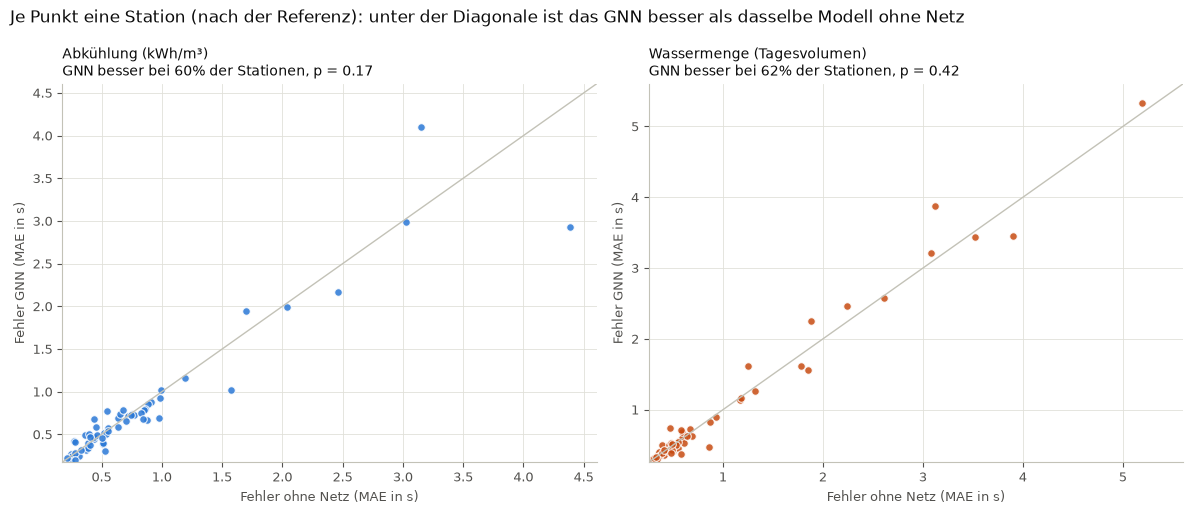

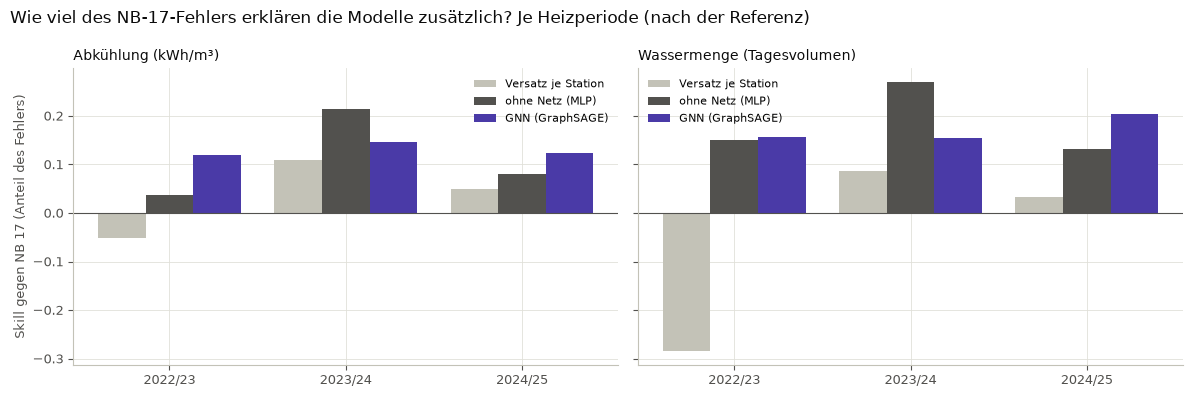

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, (kanal, titel) in zip(axes, KANAELE.items()):
    g = je_station[je_station["kanal"] == kanal]
    ax.scatter(g["mae_ohne_netz"], g["mae_gnn"], s=30, color=FARBE_KANAL[kanal], alpha=0.85,
               edgecolors="white", linewidths=0.8)
    grenzen = [min(g["mae_ohne_netz"].min(), g["mae_gnn"].min()) * 0.95,
               max(g["mae_ohne_netz"].max(), g["mae_gnn"].max()) * 1.05]
    ax.plot(grenzen, grenzen, color=ACHSE, linewidth=1)
    ax.set_xlim(grenzen)
    ax.set_ylim(grenzen)
    zeile = stationsvergleich.loc[titel]
    ax.set_title(f"{titel}\nGNN besser bei {zeile['GNN besser als ohne Netz']:.0%} der Stationen, "
                 f"p = {zeile['p (Wilcoxon GNN gegen ohne Netz)']:.2g}", loc="left", fontsize=10, color=TINTE)
    ax.set_xlabel("Fehler ohne Netz (MAE in s)", fontsize=9, color=TINTE_LEISE)
    ax.set_ylabel("Fehler GNN (MAE in s)", fontsize=9, color=TINTE_LEISE)
    stil(ax)
fig.suptitle(f"Je Punkt eine Station ({HAUPT}): unter der Diagonale ist das GNN besser als dasselbe Modell "
             "ohne Netz", x=0.01, ha="left", color=TINTE)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
breite = 0.27
for ax, titel in zip(axes, KANAELE.values()):
    g = je_saison_tab[je_saison_tab["Kanal"] == titel]
    x = np.arange(len(g))
    for versatz_x, v in [(-breite, "versatz"), (0, "ohne_netz"), (breite, "gnn")]:
        farbe = FARBE_VARIANTE["nb17"] if v == "versatz" else FARBE_VARIANTE[v]
        ax.bar(x + versatz_x, g[f"Skill {NAMEN[v]}"], breite, color=farbe, label=NAMEN[v])
    ax.axhline(0, color=TINTE_LEISE, linewidth=0.8)
    ax.set_xticks(x, g["Heizperiode"])
    ax.set_title(titel, loc="left", fontsize=10, color=TINTE)
    ax.legend(frameon=False, fontsize=8)
    stil(ax)
axes[0].set_ylabel("Skill gegen NB 17 (Anteil des Fehlers)", fontsize=9, color=TINTE_LEISE)
fig.suptitle(f"Wie viel des NB-17-Fehlers erklären die Modelle zusätzlich? Je Heizperiode ({HAUPT})",
             x=0.01, ha="left", color=TINTE)
fig.tight_layout()
plt.show()

**Wie man die Bilder liest**
- **Oben**, je Punkt eine Station: Liegen die Punkte auf der Diagonale, bringt das Netz nichts. Liegen sie klar
  darunter, hilft es.
- **Unten**, je Heizperiode, nur Tage nach der Referenz (2021/22 fehlt, weil dort alle Stationen noch in ihrer
  Referenz sind): Balken über null heißt, das Modell erklärt einen Teil des NB-17-Fehlers.
  - **dunkelgrau (ohne Netz) deutlich über null:** Die neuen eigenen Merkmale (Vortage, Vorlauf, Jahreszeit,
    Wochenende) helfen, auch ohne Netz. Das wäre eine Verbesserung für NB 17 selbst.
  - **violett (GNN) gleichbleibend höher als dunkelgrau:** Das Netz hilft.
  - **hellgrau (Versatz) deutlich niedriger als beide Modelle:** Die Modelle lernen mehr als einen festen
    Versatz je Station.

## 8 · Beispiel: der Ventilfall 68956351

- Bei dieser Station stand das Ventil rund drei Jahre offen (NB 03, 15, 17). Das Normalmodell kennt nur den
  defekten Zustand.
- **Grau** = z aus NB 17, **violett** = Rest nach der GNN-Korrektur. Werte über ±8 sind gekappt.
- Erklärt das GNN Schwankungen, die von außen kommen, wird die violette Wolke vor der Begehung schmaler als die
  graue.
- **Der Sprung nach der Begehung muss bleiben.** Er ist eine echte Änderung der Station, und das GNN darf ihn
  nicht wegerklären.

**Worauf man achten muss:** Erklärt die Korrektur nach der Begehung einen Teil des Sprungs (violett näher an
null als grau), dann kommt das vom **eigenen Vorlauf**.
- Er ist mengengewichtet. Ändert sich der Durchfluss einer Station, ändert sich auch ihr gemessener Vorlauf.
- Der eigene Vorlauf ist also nicht ganz unabhängig vom Zustand der Station.
- Für einen Alarm müsste er raus oder durch den Vorlauf der Nachbarn ersetzt werden (Abschnitt 10).

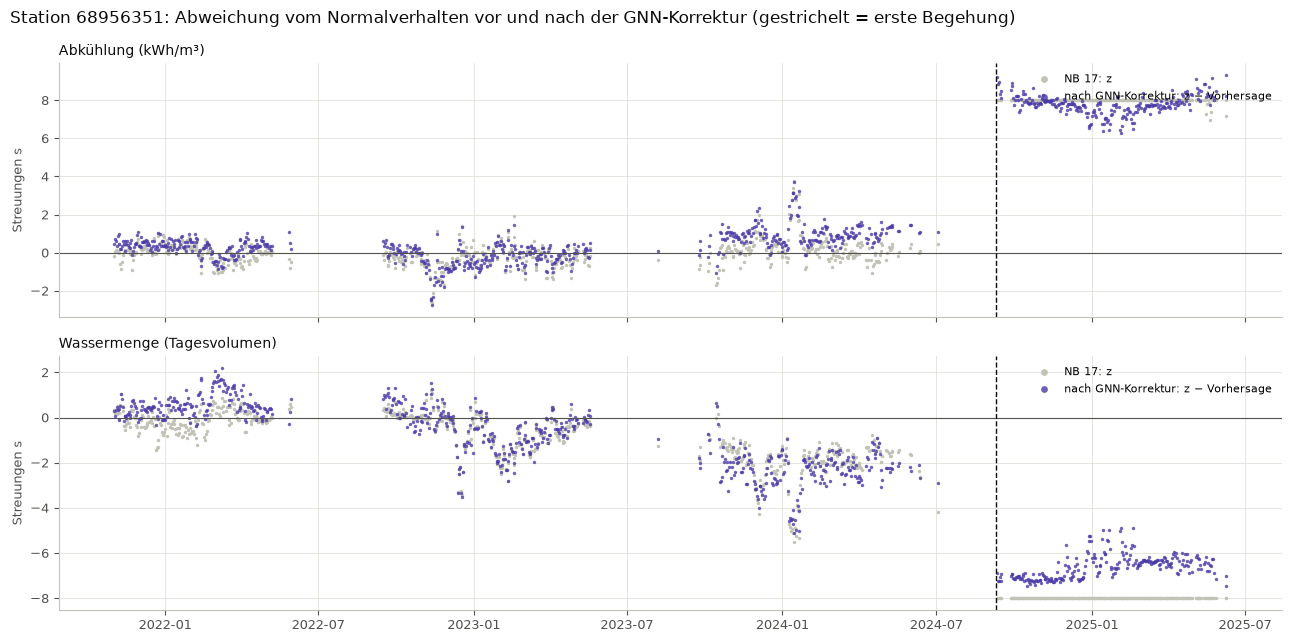

MAE nach der Referenz, vor der Begehung (s): {'Abkühlung (kWh/m³)': {'NB 17 allein': 0.53, 'Versatz je Station': 0.57, 'ohne Netz (MLP)': 0.55, 'GNN (GraphSAGE)': 0.77}, 'Wassermenge (Tagesvolumen)': {'NB 17 allein': 1.44, 'Versatz je Station': 1.26, 'ohne Netz (MLP)': 1.25, 'GNN (GraphSAGE)': 1.62}}


In [10]:
BEISPIEL = 68956351      # Ventil drei Jahre offen, Stellmotor am 09.09.2024 getauscht (NB 03, 15, 17)

if BEISPIEL not in knoten:
    print(f"{BEISPIEL} hat keinen Knoten im Netz - Beispiel entfaellt")
else:
    i = knoten.index(BEISPIEL)
    fig, axes = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)
    for c, (ax, (kanal, titel)) in enumerate(zip(axes, KANAELE.items())):
        da = np.isfinite(z[:, i, c])
        ax.scatter(tage_idx[da], Y[da, i, c], s=6, color=ACHSE, linewidths=0, label="NB 17: z")
        ax.scatter(tage_idx[da], (Y - vorhersage["gnn"])[da, i, c], s=6, color=FARBE_VARIANTE["gnn"],
                   linewidths=0, alpha=0.8, label="nach GNN-Korrektur: z − Vorhersage")
        ax.axhline(0, color=TINTE_LEISE, linewidth=0.8)
        if BEISPIEL in erste_begehung.index:
            ax.axvline(erste_begehung[BEISPIEL], color=TINTE, linestyle="--", linewidth=1)
        ax.set_ylabel("Streuungen s", fontsize=9, color=TINTE_LEISE)
        ax.set_title(titel, loc="left", fontsize=10, color=TINTE)
        ax.legend(frameon=False, fontsize=8, markerscale=2, loc="upper right")
        stil(ax)
    fig.suptitle(f"Station {BEISPIEL}: Abweichung vom Normalverhalten vor und nach der GNN-Korrektur "
                 "(gestrichelt = erste Begehung)", x=0.01, ha="left", color=TINTE)
    fig.tight_layout()
    plt.show()
    vorher = BEWERTUNG[HAUPT][:, i, :]
    print(f"MAE {HAUPT}, vor der Begehung (s):",
          {KANAELE[k]: {NAMEN[v]: round(float(fehler[v][vorher[:, c], i, c].mean()), 2) for v in fehler}
           for c, k in enumerate(KANAELE)})

## 9 · Speichern (optional)

Mit `SPEICHERN = True` (Abschnitt 1) werden die Vorhersagen je Station, Kanal und Tag nach
`data/processed/gnn_vorhersagen.csv` geschrieben, als Grundlage für einen Alarm wie in NB 17.

In [11]:
if SPEICHERN:
    zeilen = []
    for c, kanal in enumerate(KANAELE):
        for i in np.flatnonzero(ist_station):
            da = np.isfinite(z[:, i, c])
            zeilen.append(pd.DataFrame({"zaehler": knoten[i], "kanal": kanal, "datum": tage_idx[da],
                                        "z_nb17": Y[da, i, c], "vor_begehung": vor_begehung[da, i],
                                        **{f"vorhersage_{v}": vorhersage[v][da, i, c] for v in VARIANTEN}}))
    pd.concat(zeilen, ignore_index=True).to_csv(PROC / "gnn_vorhersagen.csv", index=False)
    print("gespeichert:", PROC / "gnn_vorhersagen.csv")
else:
    print("SPEICHERN = False - nichts geschrieben")

SPEICHERN = False - nichts geschrieben


## 10 · Was dieser Entwurf nicht macht, und warum

| Nicht gemacht | Warum nicht | Wann es sich lohnt |
|---|---|---|
| **Alarm (CUSUM) auf den GNN-korrigierten Abweichungen**, Treffer gegen Begehungen wie in NB 17 §9–11 | Erst muss feststehen, dass die Korrektur überhaupt etwas erklärt. Sonst ändern sich die Alarme nicht | wenn „Skill GNN“ klar über null liegt: z_neu = (z − Vorhersage) / neue Streuung, dann CUSUM wie NB 17 |
| **GNN, das die Kennlinie selbst lernt** (ohne NB 17 als Basis) | Je Station gibt es nur ein Jahr Referenz. Ein gemeinsames Netz über 80 Stationen lernt das nicht besser als die Kennlinie, und der Vergleich mit und ohne Netz wäre unschärfer | wenn es deutlich mehr Stationen oder Jahre gibt |
| **Pfeilrichtung der Kanten** (gerichtetes GNN) | Die Pfeile passen zu keiner Quelle (etwa halbe-halbe, Abschnitt 3) | wenn die ÜZ erklärt, was die Pfeile bedeuten |
| **Kantengewichte** (Rohrlänge, DN) in der Mittelung | 35 von 110 Kanten haben keinen Rohrweg. Ohne Netz-Effekt bringt eine Gewichtung nichts | wenn das GNN einen Beitrag zeigt |
| **Stundenwerte** (Spitzenlast am Morgen) | Momentaufnahmen, der Zeitstempel-Abgleich zwischen den Zählern ist ungeprüft, 24-mal mehr Daten | wenn NB 17 §16 eine Kopplung im Vorlauf zeigt |
| **Anlagendaten aus den Begehungen** (Stationstyp, Zusatzheizung, Personen) | Es gibt sie nur für die 66 begangenen Häuser, und sie wurden erst bei der Begehung erhoben. Als Merkmal würden sie „begangen ja/nein“ verraten | wenn sie für alle Häuser vorliegen |
| **PyTorch Geometric, GAT, zeitliche GNN** (z. B. GConvGRU) | PyTorch läuft auf diesem Intel-Mac nicht mit numpy 2. Bei 1–3 Nachbarn je Knoten bringt Attention wenig, und den zeitlichen Teil decken Kennlinie und Vortagstemperatur ab | auf Colab oder Linux, wenn das einfache GNN etwas zeigt |
| **Hyperparameter-Suche** | Wenig Daten. Jede Suche passt das Modell an die Prüfzeit an | nur mit eigener, vorher festgelegter Validierung |
| **Sommertage** | NB 17 modelliert nur Heiztage | mit einem Sommerkanal in NB 17 |
| **Training nur auf Tagen nach der Referenz** | Im Referenzjahr ist z „im Lernzeitraum“ der Kennlinie und kleiner. Gelernt wurde auf allen Tagen vor der Begehung, damit die Lernmenge nicht halbiert wird | beim zweiten Lauf, mit vorher festgelegter Bewertung |
| **Merkmale einzeln weglassen** (welches Merkmal bringt den Skill?) | Jeder Lauf dauert eine Viertelstunde. Erst sollte die Grundfrage „Netz ja/nein“ beantwortet sein | als Nächstes für die Merkmale ohne Netz: Vortage, Vorlauf, Jahreszeit |
| **eigener Vorlauf ohne Rückwirkung** | Der mengengewichtete Vorlauf hängt am eigenen Durchfluss (Abschnitt 8) | vor jedem Alarm: eigenen Vorlauf weglassen oder nur den der Nachbarn nehmen |

## 11 · Was fehlt, um weiterzukommen

| Was | Wofür | Woher |
|---|---|---|
| **Lage der Heizzentrale und der Einspeisepunkte** | Rohrweg und „Last dahinter“ exakt statt mit der Annahme „Schule“ | ÜZ, Netzplan |
| **Bedeutung der Pfeile** in `Nodes_Edges.ods` | gerichtetes GNN: Vorlauf fließt nur stromab | ÜZ |
| **Koordinaten der 18 Adressen ohne Position** | Rohrweg für die 35 Kanten ohne Länge | `fehlende_koordinaten_*.ods` ausfüllen, NB 16 neu laufen lassen |
| **Vorlauftemperatur am Ausgang der Heizzentrale** | erklärt netzweite Schwankungen direkt, statt über den Flottenmedian | Leitsystem der Heizzentrale |
| **Rohrdaten je Kante** (DN, Länge, Baujahr) | Kantengewichte, hydraulischer Widerstand | KML/Shapefile (teilweise vorhanden, NB 16) |
| **Begehungen nach Juli 2025 mit Zählerständen** | ungesehene Prüffälle für die Alarme | ÜZ |

## 12 · Ergebnis *(nach dem ersten Lauf ausfüllen)*

- **Skill ohne Netz (neue eigene Merkmale):** …
- **Beitrag des Netzes (GNN gegen ohne Netz), p je Kanal:** …
- **Ventilfall:** …
- **Folgerung:** …